# Daily One-Day-Ahead Wind Speed Forecasting — NWTC M2

Replikasi ringan Altork (2025) pada data bulanan, lalu ekstensi utama: peramalan
kecepatan angin harian satu hari ke depan (t+1) di NREL/NLR National Wind
Technology Center M2, Boulder, Colorado (2019–2023).

Sumber data: MIDC `https://midcdmz.nlr.gov/apps/data_api.pl?site=NWTC`.
Dataset diproduksi oleh `scripts/download_data.py`; notebook ini tidak mengunduh data.


## 1. Setup

Konfigurasi path, seed, dan import untuk seluruh notebook. Import baru untuk section berikutnya ditambahkan di sini agar notebook tetap bisa dieksekusi dari atas ke bawah.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, TimeSeriesSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

DATA_DIR = Path("data/processed")
FIG_DIR = Path("results/figures")
RESULTS_DIR = Path("results")
RANDOM_STATE = 42

FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## 2. Data Loading and Quality

`daily.csv` dan `monthly.csv` dihasilkan `scripts/download_data.py` dari export 1 menit MIDC. Assertion di bawah mengunci bentuk dataset.

In [2]:
daily = pd.read_csv(DATA_DIR / "daily.csv", parse_dates=["date"], index_col="date")
monthly = pd.read_csv(DATA_DIR / "monthly.csv", index_col="month")
monthly.index = pd.PeriodIndex(monthly.index, freq="M")
quality = pd.read_csv(DATA_DIR / "data_quality.csv")

assert len(daily) == 1826
assert len(monthly) == 60
assert len(quality) == 60
assert daily.index.min() == pd.Timestamp("2019-01-01")
assert daily.index.max() == pd.Timestamp("2023-12-31")
assert monthly.index.min() == pd.Period("2019-01", "M")
assert monthly.index.max() == pd.Period("2023-12", "M")
assert not daily.index.duplicated().any()

display(daily.head())
display(monthly.head())
display(quality.head())

,wind_speed_50m,wind_dir_deg,wind_dir_sin,wind_dir_cos,temperature_50m,relative_humidity,pressure,precipitation,n_valid_minutes,completeness
date,,,,,,,,,,
2019-01-01,1.456649,137.900011,0.670426,-0.741976,-14.284154,71.617563,812.663540,0.000,1440,1.0
2019-01-02,2.470028,250.340149,-0.941707,-0.336435,-1.061922,42.507257,811.720479,2.540,1440,1.0
2019-01-03,2.955379,261.396810,-0.988748,-0.149590,6.567799,31.810069,811.304703,0.762,1440,1.0
2019-01-04,3.437153,292.760810,-0.922128,0.386885,11.113537,25.410889,811.827401,0.000,1440,1.0
2019-01-05,2.498463,328.467488,-0.522982,0.852344,10.110012,26.780938,811.307790,0.000,1440,1.0


,wind_speed_50m,wind_dir_deg,wind_dir_sin,wind_dir_cos,temperature_50m,relative_humidity,pressure,precipitation,n_valid_minutes,completeness
month,,,,,,,,,,
2019-01,4.901771,285.218506,-0.964932,0.262501,2.244921,45.962357,811.964664,33.022,44640,1.0
2019-02,4.350938,329.941189,-0.500889,0.865512,-1.525074,53.232528,806.386784,7.620,40320,1.0
2019-03,3.419137,352.690688,-0.127226,0.991874,1.562742,57.794549,812.846325,54.618,44640,1.0
2019-04,4.076535,340.259863,-0.337755,0.941234,8.584396,54.393300,810.724961,30.222,43200,1.0
2019-05,3.519509,340.867599,-0.327752,0.944764,9.483338,63.261168,810.783454,97.546,44640,1.0


,year,month,expected_minutes,n_rows,n_missing_minutes,n_duplicate_minutes,valid_wind_speed,valid_wind_dir,valid_temperature,valid_humidity,valid_pressure,valid_precipitation
0,2019,1,44640,44640,0,0,44640,44640,44640,44640,44640,44640
1,2019,2,40320,40320,0,0,40320,40320,40320,40320,40320,40320
2,2019,3,44640,44640,0,0,44640,44640,44640,44640,44640,44640
3,2019,4,43200,43200,0,0,43200,43200,43200,43200,43200,43200
4,2019,5,44640,44640,0,0,44640,44640,44640,44640,44640,44640


In [3]:
missing_daily = daily.isna().sum().to_frame("missing_days")
missing_daily["missing_pct"] = (missing_daily["missing_days"] / len(daily) * 100).round(2)

print(f"daily: {len(daily)} hari, {daily.index.min().date()} -> {daily.index.max().date()}")
print(f"monthly: {len(monthly)} bulan, {monthly.index.min()} -> {monthly.index.max()}")
display(missing_daily.T)
display(monthly.isna().sum().to_frame("missing_months").T)

daily: 1826 hari, 2019-01-01 -> 2023-12-31
monthly: 60 bulan, 2019-01 -> 2023-12


,wind_speed_50m,wind_dir_deg,wind_dir_sin,wind_dir_cos,temperature_50m,relative_humidity,pressure,precipitation,n_valid_minutes,completeness
missing_days,0.0,0.0,0.0,0.0,19.00,2.00,0.0,0.0,0.0,0.0
missing_pct,0.0,0.0,0.0,0.0,1.04,0.11,0.0,0.0,0.0,0.0


,wind_speed_50m,wind_dir_deg,wind_dir_sin,wind_dir_cos,temperature_50m,relative_humidity,pressure,precipitation,n_valid_minutes,completeness
missing_months,0,0,0,0,0,0,0,0,0,0


Coverage per bulan: `valid_wind_speed / expected_minutes` dari `data_quality.csv`.

In [4]:
coverage = quality.assign(valid_fraction=quality["valid_wind_speed"] / quality["expected_minutes"])
display(coverage.nsmallest(5, "valid_fraction")[["year", "month", "n_rows", "n_duplicate_minutes", "valid_fraction"]])
print("bulan dengan menit duplikat di sumber:", int((coverage["n_duplicate_minutes"] > 0).sum()))

,year,month,n_rows,n_duplicate_minutes,valid_fraction
7,2019,8,44580,60,0.998656
28,2021,5,44625,0,0.999664
30,2021,7,44640,0,0.999754
50,2023,3,44631,0,0.999798
0,2019,1,44640,0,1.000000


bulan dengan menit duplikat di sumber: 2


## 3. Exploratory Data Analysis

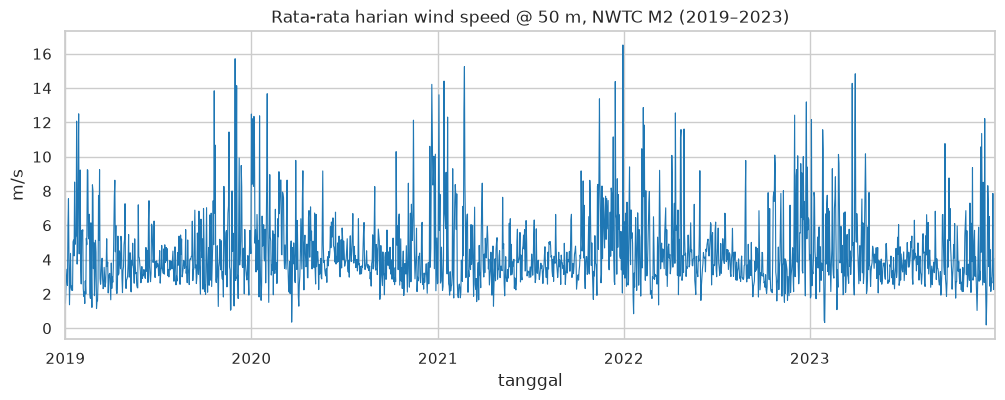

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
daily["wind_speed_50m"].plot(ax=ax, linewidth=0.8, color="tab:blue")
ax.set_title("Rata-rata harian wind speed @ 50 m, NWTC M2 (2019–2023)")
ax.set_xlabel("tanggal")
ax.set_ylabel("m/s")
fig.savefig(FIG_DIR / "fig_daily_wind_speed.png", dpi=150, bbox_inches="tight")
plt.show()

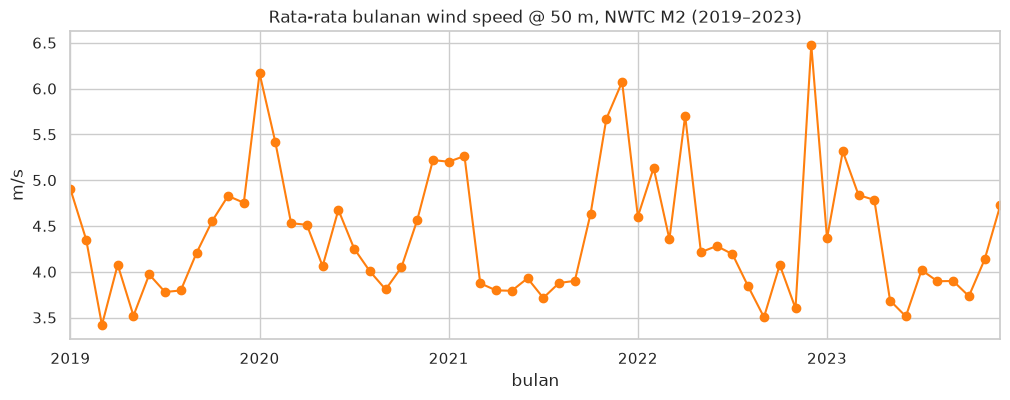

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
daily["wind_speed_50m"].resample("MS").mean().plot(ax=ax, marker="o", color="tab:orange")
ax.set_title("Rata-rata bulanan wind speed @ 50 m, NWTC M2 (2019–2023)")
ax.set_xlabel("bulan")
ax.set_ylabel("m/s")
fig.savefig(FIG_DIR / "fig_monthly_wind_speed.png", dpi=150, bbox_inches="tight")
plt.show()

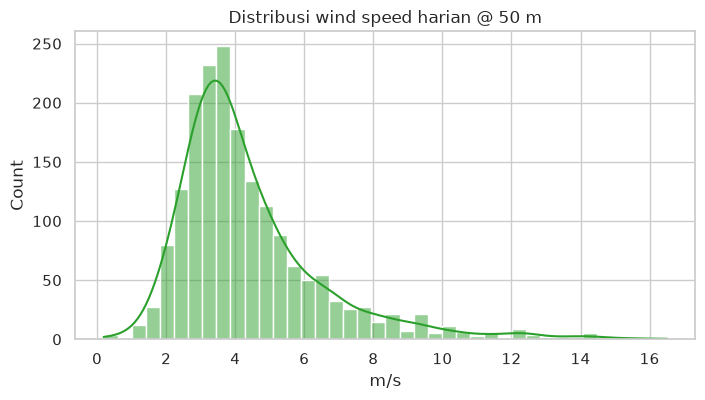

count    1826.000000
mean        4.396697
std         2.141774
min         0.189000
25%         3.044868
50%         3.821707
75%         5.116961
max        16.510985
Name: wind_speed_50m, dtype: float64

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(daily["wind_speed_50m"].dropna(), bins=40, kde=True, ax=ax, color="tab:green")
ax.set_title("Distribusi wind speed harian @ 50 m")
ax.set_xlabel("m/s")
fig.savefig(FIG_DIR / "fig_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

daily["wind_speed_50m"].describe()

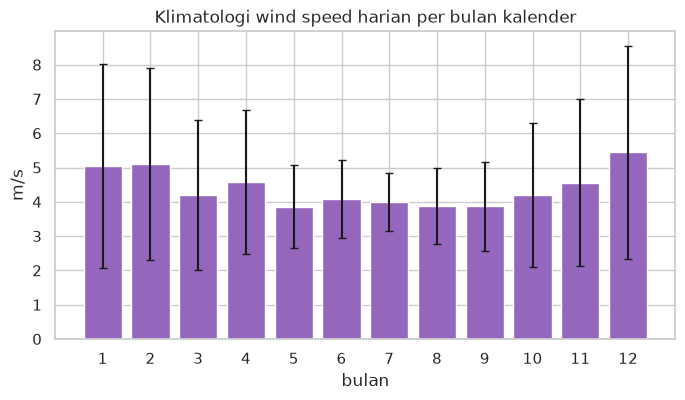

,mean,std,count
date,,,
1,5.047,2.979,155
2,5.098,2.806,141
3,4.203,2.180,155
4,4.575,2.106,150
5,3.855,1.210,155
6,4.074,1.140,150
7,3.992,0.835,155
8,3.883,1.115,155
9,3.863,1.307,150


In [8]:
climatology = daily.groupby(daily.index.month)["wind_speed_50m"].agg(["mean", "std", "count"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(climatology.index, climatology["mean"], yerr=climatology["std"], capsize=3, color="tab:purple")
ax.set_xticks(range(1, 13))
ax.set_xlabel("bulan")
ax.set_ylabel("m/s")
ax.set_title("Klimatologi wind speed harian per bulan kalender")
fig.savefig(FIG_DIR / "fig_monthly_climatology.png", dpi=150, bbox_inches="tight")
plt.show()

climatology.round(3)

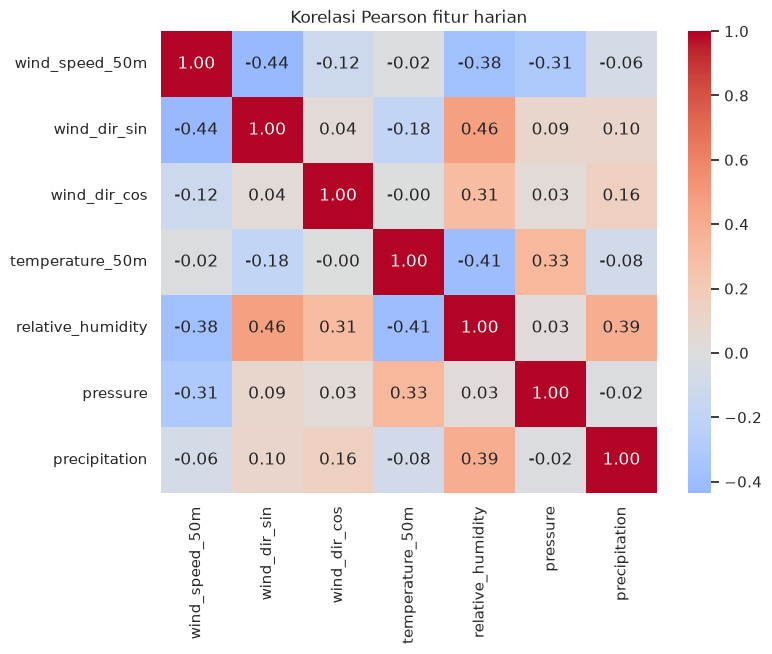

,pearson_r
wind_speed_50m,1.000
temperature_50m,-0.018
precipitation,-0.065
wind_dir_cos,-0.122
pressure,-0.306
relative_humidity,-0.381
wind_dir_sin,-0.436


In [9]:
CORR_COLS = [
    "wind_speed_50m", "wind_dir_sin", "wind_dir_cos", "temperature_50m",
    "relative_humidity", "pressure", "precipitation",
]
corr = daily[CORR_COLS].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Korelasi Pearson fitur harian")
fig.savefig(FIG_DIR / "fig_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

corr["wind_speed_50m"].sort_values(ascending=False).to_frame("pearson_r").round(3)

## 4. Monthly Sanity Check (Replication)

Replikasi ringan Altork (2025): 60 observasi bulanan, lima input seperti paper,
split acak 70/15/15 dengan `random_state=42`. Split acak **disengaja** di sini
untuk meniru paper; eksperimen utama di section 5 memakai split kronologis.

Angka paper tidak harus identik karena paper tidak merinci hyperparameter,
split, dan detail agregasi.

### 4.1 Dataset dan split

In [10]:
sanity_features = ["pressure", "temperature_50m", "wind_dir_deg", "relative_humidity", "precipitation"]
sanity_target = "wind_speed_50m"

sanity = monthly.dropna(subset=sanity_features + [sanity_target]).copy()
print("sanity observations:", len(sanity))

X = sanity[sanity_features]
y = sanity[sanity_target]

# 70/15/15 seperti paper: 60 observasi -> 42 train / 9 validation / 9 test.
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=len(X_test) / len(X_trainval), random_state=RANDOM_STATE
)
print("train/val/test:", len(X_train), len(X_val), len(X_test))


sanity observations: 60
train/val/test: 42 9 9


### 4.2 Model

Scaler hanya di-fit pada train lewat pipeline; model final di-refit pada train+validation dengan pipeline baru.

In [11]:
def sanity_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "RMSE": float(np.sqrt(mse)),
        "MSE": float(mse),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }


sanity_trainval = (pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
sanity_results_rows = []

def sanity_fit_and_evaluate(name, estimator, param_grid=None):
    if param_grid is None:
        search = estimator
    else:
        search = GridSearchCV(
            estimator,
            param_grid,
            cv=KFold(3, shuffle=True, random_state=RANDOM_STATE),
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
        )
    search.fit(X_train, y_train)
    fitted = search.best_estimator_ if param_grid is not None else search
    val_metrics = sanity_metrics(y_val, fitted.predict(X_val))

    final = clone(fitted).fit(*sanity_trainval)
    test_metrics = sanity_metrics(y_test, final.predict(X_test))
    sanity_results_rows.append({"model": name, **test_metrics})
    print(f"{name}: validation RMSE {val_metrics['RMSE']:.4f} | test RMSE {test_metrics['RMSE']:.4f}")
    return final


sanity_final_models = {
    "Linear Regression": sanity_fit_and_evaluate(
        "Linear Regression", make_pipeline(MinMaxScaler(feature_range=(-1, 1)), LinearRegression())
    ),
    "SVR": sanity_fit_and_evaluate(
        "SVR",
        make_pipeline(MinMaxScaler(feature_range=(-1, 1)), SVR(kernel="rbf")),
        {"svr__C": [1, 10, 100], "svr__gamma": ["scale", 0.1], "svr__epsilon": [0.01, 0.1]},
    ),
    "Fine Tree": sanity_fit_and_evaluate(
        "Fine Tree",
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {"max_depth": [None, 3, 5, 10], "min_samples_leaf": [1, 2, 4]},
    ),
}

Linear Regression: validation RMSE 0.4708 | test RMSE 0.4923


SVR: validation RMSE 0.4389 | test RMSE 0.5372
Fine Tree: validation RMSE 0.5008 | test RMSE 0.5156


### 4.3 Pelaporan

In [12]:
sanity_results = pd.DataFrame(sanity_results_rows).sort_values("RMSE").reset_index(drop=True)

paper_reference = pd.DataFrame([
    {"model": "Linear Regression", "paper_RMSE": 0.29555, "paper_MSE": 0.087352, "paper_MAE": 0.18061, "paper_R2": 0.97},
    {"model": "SVR", "paper_RMSE": 0.32275, "paper_MSE": np.nan, "paper_MAE": np.nan, "paper_R2": 0.96},
    {"model": "Fine Tree", "paper_RMSE": 0.44042, "paper_MSE": np.nan, "paper_MAE": np.nan, "paper_R2": 0.93},
])

display(sanity_results.round(4))
display(paper_reference)

assert np.isfinite(sanity_results[["RMSE", "MSE", "MAE", "R2"]].to_numpy()).all()
lr_r2 = sanity_results.loc[sanity_results["model"] == "Linear Regression", "R2"].iloc[0]
# Batas atas menangkap leakage (R2 ~ 1). Batas bawah hanya menuntut model lebih baik
# dari rata-rata: pada 9 observasi test, R2 terlalu tidak stabil untuk ambang lebih ketat.
assert 0.0 < lr_r2 < 0.999, f"R2 Linear Regression di luar rentang wajar: {lr_r2}"
print(f"catatan: test hanya {len(y_test)} observasi bulanan; R2 tidak stabil pada n={len(y_test)}")
print(f"standar deviasi target test: {y_test.std():.4f} m/s")

sanity_results.to_csv(RESULTS_DIR / "sanity_check_metrics.csv", index=False)
print("tersimpan:", RESULTS_DIR / "sanity_check_metrics.csv")


,model,RMSE,MSE,MAE,R2
0,Linear Regression,0.4923,0.2424,0.3380,0.4819
1,Fine Tree,0.5156,0.2658,0.4189,0.4318
2,SVR,0.5372,0.2886,0.3754,0.3831


,model,paper_RMSE,paper_MSE,paper_MAE,paper_R2
0,Linear Regression,0.29555,0.087352,0.18061,0.97
1,SVR,0.32275,NaN,NaN,0.96
2,Fine Tree,0.44042,NaN,NaN,0.93


catatan: test hanya 9 observasi bulanan; R2 tidak stabil pada n=9
standar deviasi target test: 0.7255 m/s
tersimpan: results/sanity_check_metrics.csv
